# New `streamspraydf` features: time-dependent mass & non-uniform stripping

This notebook walks through two new features added to `galpy.df.streamspraydf` in PRs [#880](https://github.com/jobovy/galpy/pull/880) and [#881](https://github.com/jobovy/galpy/pull/881):

1. **Time-dependent progenitor mass** — `progenitor_mass` now accepts a callable `M(t)`.
2. **Non-uniform stripping times** — a new `stripping_pdf=` keyword draws stripping times from an arbitrary 1D distribution over the disruption window.

Both accept astropy `Quantity` input/output, auto-detected from the callable's signature.

To make differences between runs easier to read, the morphology plots use the **orbit-aligned (φ₁, φ₂) frame** — `Orbit.align_to_orbit()` produces a rotation matrix that aligns φ₁ with the progenitor's orbital plane and places the progenitor at φ₁=180° (the default). We also overlay each spray DF's smooth `streamTrack` with a ±1σ φ₂ envelope so the mean tracks and widths are directly comparable, not just the scatter.

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")
import numpy
import matplotlib.pyplot as plt
from astropy import units as u

from galpy.df import chen24spraydf, fardal15spraydf, pericenter_stripping_pdf
from galpy.potential import LogarithmicHaloPotential
from galpy.orbit import Orbit
from galpy.util import conversion

ro, vo = 8.0, 220.0
lp = LogarithmicHaloPotential(normalize=1.0, q=0.9)
prog = Orbit(
    [1.56148083, 0.35081535, -1.15481504, 0.88719443, -0.47713334, 0.12019596],
    ro=ro, vo=vo,
)
tdisrupt = 4.5 * u.Gyr
M0 = 2e4 * u.Msun

# Build the rotation matrix that aligns the orbit's plane with φ₁.
# center_phi1=180 (the default) places the progenitor at φ₁=180°.
T_orbit = prog.align_to_orbit(center_phi1=180.0)

## Part 1 — Time-dependent progenitor mass (PR #880)

`progenitor_mass` accepts a callable `M(t)`. Time convention matches galpy's internal one: `t=0` is now, `t<0` is the past. Both input and output of the callable may be astropy `Quantity` — detection is automatic, the same way `AnyAxisymmetricRazorThinDiskPotential` does it for its `surfdens` callable.

Three valid signatures, all equivalent here:

```python
M_internal_only = lambda t: M0_internal * f(t)                 # both unitless
M_unitful_in    = lambda t: M0_internal * f(t.to(u.Gyr).value) # takes Quantity, returns float
M_unitful_out   = lambda t: M0 * f(t * conversion.time_in_Gyr(vo, ro))  # takes float, returns Quantity
M_unitful_both  = lambda t: M0 * f(t.to(u.Gyr).value)          # both Quantity
```

Here we contrast a constant-mass progenitor with one whose mass **decreases over time** — a realistic picture of tidal mass loss. The progenitor starts disruption ~5× more massive and ends at $M_0$ today, following an exponential decay with a 2.5 Gyr e-folding time.

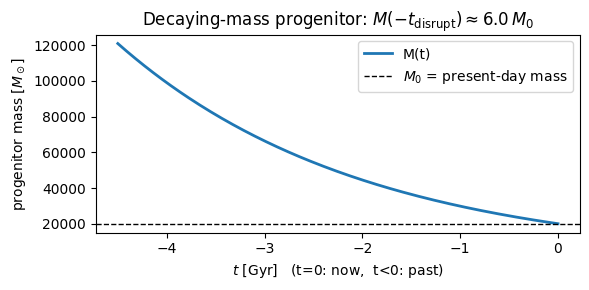

In [2]:
tau = 2.5 * u.Gyr  # e-folding time
M_init = M0 * numpy.exp(tdisrupt / tau)  # mass at t = -tdisrupt (start of disruption)

def M_decaying(t):
    # t = Quantity time, t <= 0 (t=0: now, t<0: past).
    # M(0) = M0; M(-tdisrupt) ≈ 5 * M0; exponential in between.
    return M0 * numpy.exp(-t / tau)

# Show the mass curve.
t_grid = numpy.linspace(-tdisrupt.value, 0.0, 200) * u.Gyr
plt.figure(figsize=(6, 3))
plt.plot(t_grid.value, M_decaying(t_grid).to_value(u.Msun), color='C0', lw=2, label='M(t)')
plt.axhline(M0.to_value(u.Msun), color='k', ls='--', lw=1, label='$M_0$ = present-day mass')
plt.xlabel('$t$ [Gyr]   (t=0: now,  t<0: past)')
plt.ylabel('progenitor mass [$M_\\odot$]')
plt.title(f'Decaying-mass progenitor: $M(-t_\\mathrm{{disrupt}}) \\approx {(M_init/M0).value:.1f}\\,M_0$')
plt.legend()
plt.tight_layout();

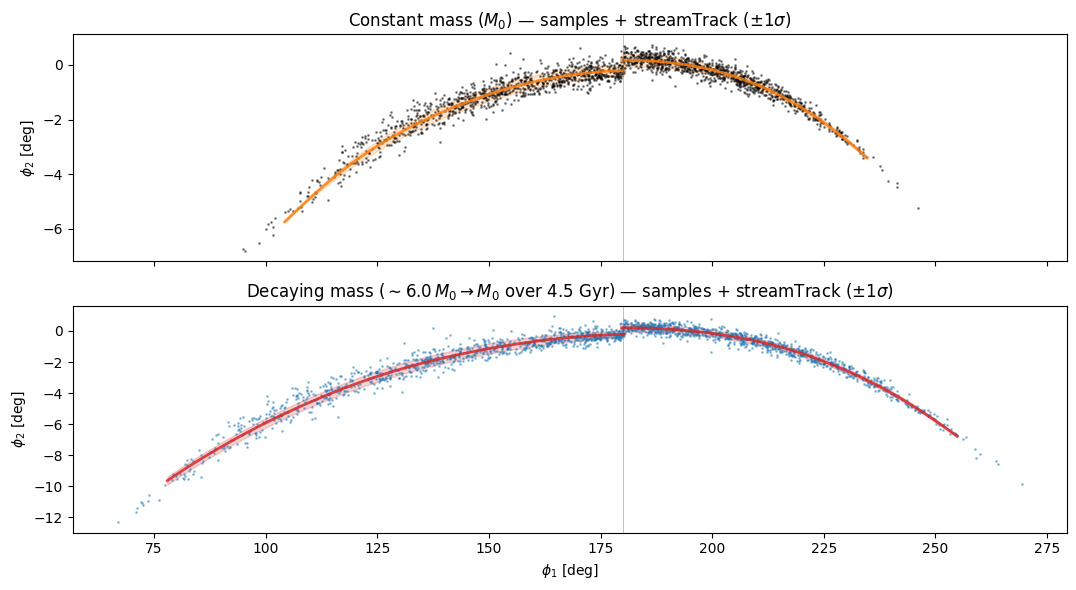

In [3]:
# Helper: get aligned (phi1, phi2) for a sampled stream Orbit (at t=0).
def aligned(stream):
    return stream.phi1(T=T_orbit, t=0., use_physical=True), stream.phi2(T=T_orbit, t=0., use_physical=True)

# Sample streams and build smooth streamTracks for both DFs.
spdf_const = chen24spraydf(
    progenitor_mass=M0, progenitor=prog, pot=lp,
    tdisrupt=tdisrupt, tail='both', ro=ro, vo=vo,
)
spdf_evol = chen24spraydf(
    progenitor_mass=M_decaying, progenitor=prog, pot=lp,
    tdisrupt=tdisrupt, tail='both', ro=ro, vo=vo,
)

numpy.random.seed(1)
stream_const = spdf_const.sample(n=2000)
numpy.random.seed(1)
stream_evol = spdf_evol.sample(n=2000)

numpy.random.seed(11)
track_const = spdf_const.streamTrack(n=500, custom_sky_transform=T_orbit)
numpy.random.seed(11)
track_evol = spdf_evol.streamTrack(n=500, custom_sky_transform=T_orbit)

phi1_const, phi2_const = aligned(stream_const)
phi1_evol, phi2_evol = aligned(stream_evol)

def _draw_track(ax, track, color):
    # track is a StreamTrackPair (tail='both'); plot each arm with ±1σ band.
    plt.sca(ax)
    for arm_name in ('leading', 'trailing'):
        arm = getattr(track, arm_name)
        arm.plot(d1='phi1', d2='phi2', spread=1, color=color, lw=2.0, alpha=0.85)

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
plt.sca(axes[0])
axes[0].plot(phi1_const, phi2_const, 'k.', ms=2, alpha=0.4)
_draw_track(axes[0], track_const, 'C1')
axes[0].axvline(180, color='r', lw=0.5, alpha=0.5)
axes[0].set_ylabel('$\\phi_2$ [deg]')
axes[0].set_title('Constant mass ($M_0$) — samples + streamTrack (±1$\\sigma$)')
plt.sca(axes[1])
axes[1].plot(phi1_evol, phi2_evol, 'C0.', ms=2, alpha=0.4)
_draw_track(axes[1], track_evol, 'C3')
axes[1].axvline(180, color='r', lw=0.5, alpha=0.5)
axes[1].set_xlabel('$\\phi_1$ [deg]')
axes[1].set_ylabel('$\\phi_2$ [deg]')
axes[1].set_title(f'Decaying mass ($\\sim {(M_init/M0).value:.1f}\\,M_0 \\to M_0$ over {tdisrupt.value:g} Gyr) — samples + streamTrack (±1$\\sigma$)')
plt.tight_layout();

**What changed**: with a *higher* mass in the distant past, the tidal radius at early stripping events is **larger** (`r_t \propto M^{1/3}`), and in the Chen-24 model the escape-velocity kick is correspondingly larger. The decaying-mass stream therefore has a wider φ₂ envelope at the far ends of the arms (large |φ₁|), where the oldest strippings dominate — and a similar central width near φ₁=0 where the most recent strippings (with $M \approx M_0$) live.

Comparing the two panels side-by-side in the orbit-aligned frame makes this immediately visible: the bottom panel is "fatter" at the wings.

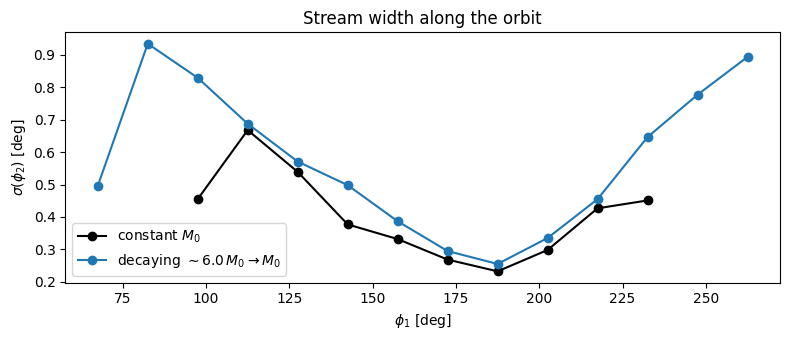

In [4]:
# Quantitative: φ₂ scatter as a function of arc length φ₁.
def binned_std(phi1, phi2, edges):
    cs = numpy.zeros(len(edges)-1)
    for i in range(len(edges)-1):
        m = (phi1 >= edges[i]) & (phi1 < edges[i+1])
        cs[i] = numpy.std(phi2[m]) if m.sum() > 3 else numpy.nan
    return cs

edges = numpy.linspace(0, 360, 25)
centers = 0.5 * (edges[:-1] + edges[1:])
std_const = binned_std(phi1_const, phi2_const, edges)
std_evol = binned_std(phi1_evol, phi2_evol, edges)

plt.figure(figsize=(8, 3.5))
plt.plot(centers, std_const, 'ko-', label='constant $M_0$')
plt.plot(centers, std_evol, 'C0o-', label=f'decaying $\\sim{(M_init/M0).value:.1f}\\,M_0 \\to M_0$')
plt.xlabel('$\\phi_1$ [deg]')
plt.ylabel('$\\sigma(\\phi_2)$ [deg]')
plt.title('Stream width along the orbit')
plt.legend()
plt.tight_layout();

In [5]:
# Sanity: legacy attribute still works and reports M(t=0).
print('spdf_evol._progenitor_mass (internal units):', spdf_evol._progenitor_mass)
print('M(0)        in Msun:', M_decaying(0*u.Gyr).to_value(u.Msun))
print('M(-tdisrupt) in Msun:', M_decaying(-tdisrupt).to_value(u.Msun))

spdf_evol._progenitor_mass (internal units): 2.2215481766716324e-07
M(0)        in Msun: 20000.0
M(-tdisrupt) in Msun: 120992.94928825893


## Part 2 — Non-uniform stripping times (PR #881)

By default `streamspraydf` draws stripping times uniformly over `[-tdisrupt, 0]`. The new `stripping_pdf=` keyword lets you supply any 1D density over that interval. The constructor evaluates it on a 10 001-point grid, builds an inverse-CDF spline once, and `_sample_tail` then draws times via inverse-CDF sampling.

The PDF must be non-negative on `[-tdisrupt, 0]` and have non-zero integral. It does **not** need to be normalized. Quantity in/out are auto-detected.

### Example 1 — a custom Gaussian window

Pretend you have an external simulation that says most of the mass was lost in a ~600 Myr episode centered 2.5 Gyr ago. Just hand that as a PDF.

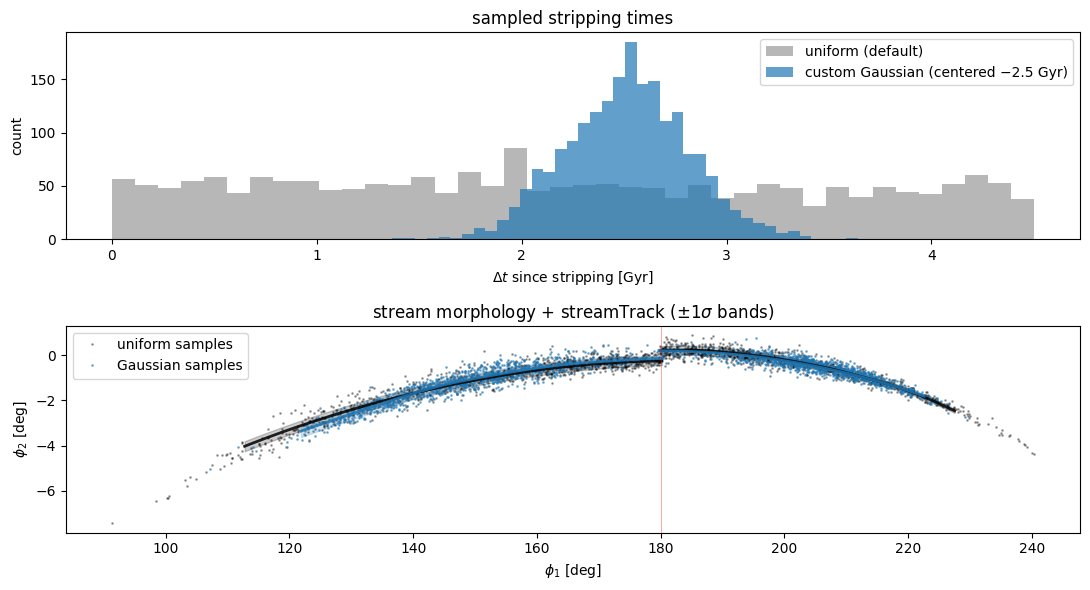

In [6]:
def gauss_pdf(t):
    # t is a Quantity time (auto-detected); return a Quantity 1/time.
    return numpy.exp(-0.5 * ((t - (-2.5*u.Gyr)) / (0.3*u.Gyr))**2) / u.Gyr

spdf_gauss = chen24spraydf(
    progenitor_mass=M0, progenitor=prog, pot=lp,
    tdisrupt=tdisrupt, stripping_pdf=gauss_pdf, tail='both',
    ro=ro, vo=vo,
)
spdf_uniform = chen24spraydf(
    progenitor_mass=M0, progenitor=prog, pot=lp,
    tdisrupt=tdisrupt, tail='both',
    ro=ro, vo=vo,
)

numpy.random.seed(2)
stream_gauss, dt_gauss = spdf_gauss.sample(n=2000, returndt=True)
numpy.random.seed(2)
stream_uniform, dt_uniform = spdf_uniform.sample(n=2000, returndt=True)

numpy.random.seed(22)
track_uniform = spdf_uniform.streamTrack(n=500, custom_sky_transform=T_orbit)
numpy.random.seed(22)
track_gauss = spdf_gauss.streamTrack(n=500, custom_sky_transform=T_orbit)

# dt is in internal time units when return_orbit=True; convert to Gyr by hand.
gyr = conversion.time_in_Gyr(vo, ro)

phi1_u, phi2_u = aligned(stream_uniform)
phi1_g, phi2_g = aligned(stream_gauss)

fig, axes = plt.subplots(2, 1, figsize=(11, 6))
# Top: dt histograms
axes[0].hist(dt_uniform * gyr, bins=40, color='0.6', alpha=0.7, label='uniform (default)')
axes[0].hist(dt_gauss * gyr, bins=40, color='C0', alpha=0.7, label='custom Gaussian (centered −2.5 Gyr)')
axes[0].set_xlabel(r'$\Delta t$ since stripping [Gyr]')
axes[0].set_ylabel('count')
axes[0].set_title('sampled stripping times')
axes[0].legend()
# Bottom: orbit-aligned morphology + streamTrack overlay
plt.sca(axes[1])
axes[1].plot(phi1_u, phi2_u, 'k.', ms=2, alpha=0.3, label='uniform samples')
axes[1].plot(phi1_g, phi2_g, 'C0.', ms=2, alpha=0.5, label='Gaussian samples')
_draw_track(axes[1], track_uniform, 'k')
_draw_track(axes[1], track_gauss, 'C0')
axes[1].axvline(180, color='r', lw=0.5, alpha=0.5)
axes[1].set_xlabel(r'$\phi_1$ [deg]')
axes[1].set_ylabel(r'$\phi_2$ [deg]')
axes[1].set_title('stream morphology + streamTrack (±1$\\sigma$ bands)')
axes[1].legend(loc='best')
plt.tight_layout();

The Gaussian-stripping stream sits as a tight cluster in the φ₁ range corresponding to ~2.5 Gyr of stream age. The uniform default fills out the full φ₁ envelope from the progenitor to the leading/trailing tips.

### Example 2 — pericenter-driven stripping via `pericenter_stripping_pdf`

Real tidal stripping is enhanced around pericenter passages. Building that PDF by hand is tedious: you need to integrate the progenitor, locate pericenters, choose a width, and write a normalized Gaussian mixture. PR #881 adds a helper that does all of that for you:

```python
pericenter_stripping_pdf(progenitor, pot, tdisrupt, sigma)
```

Returns a callable PDF that is a sum of equal-height Gaussians centered on every pericenter passage of `progenitor` over `[-tdisrupt, 0]`. The PDF is **hard-cut to zero** outside the disruption window so it carries no weight beyond `tdisrupt`. The pericenter times are exposed on `pdf.pericenter_times` for inspection.

In [7]:
peri_pdf = pericenter_stripping_pdf(
    progenitor=prog, pot=lp,
    tdisrupt=tdisrupt,
    sigma=80*u.Myr,
)
peri_times_gyr = peri_pdf.pericenter_times * conversion.time_in_Gyr(vo, ro)
print(f'Found {len(peri_times_gyr)} pericenter passages over [-4.5, 0] Gyr.')
print('Pericenter times [Gyr]:', numpy.round(peri_times_gyr, 3))

# Verify the cutoff.
print()
print('PDF at t = +0.1 Gyr (outside window):', peri_pdf(0.1*u.Gyr))
print('PDF at t = -5.0 Gyr (outside window):', peri_pdf(-5.0*u.Gyr))

Found 12 pericenter passages over [-4.5, 0] Gyr.
Pericenter times [Gyr]: [-0.006 -0.417 -0.808 -1.217 -1.609 -2.016 -2.411 -2.817 -3.212 -3.616
 -4.014 -4.416]

PDF at t = +0.1 Gyr (outside window): 0.0 1 / Gyr
PDF at t = -5.0 Gyr (outside window): 0.0 1 / Gyr


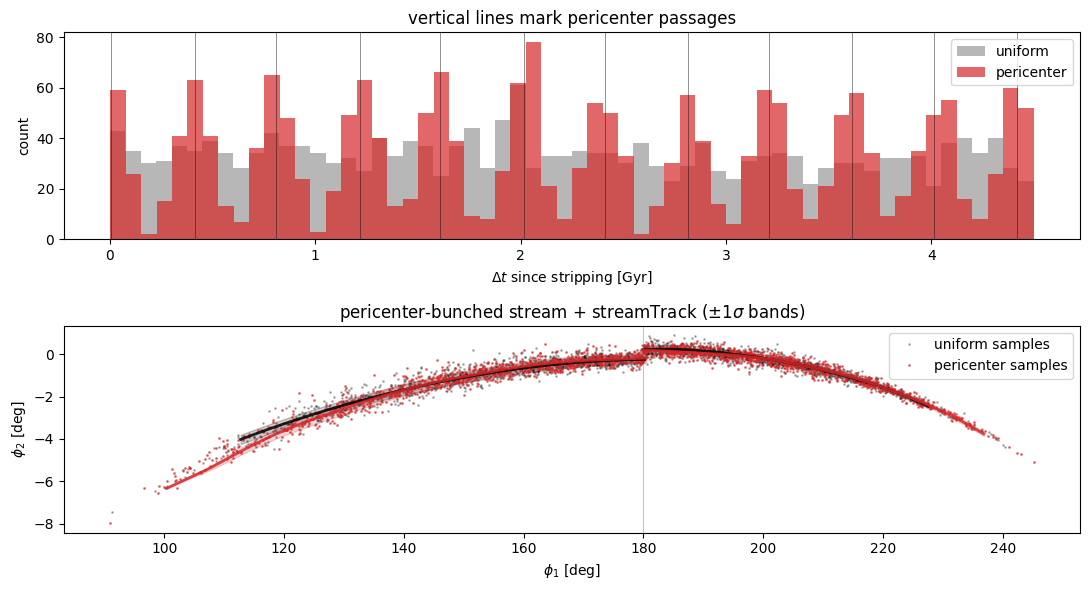

In [8]:
spdf_peri = chen24spraydf(
    progenitor_mass=M0, progenitor=prog, pot=lp,
    tdisrupt=tdisrupt, stripping_pdf=peri_pdf, tail='both',
    ro=ro, vo=vo,
)
numpy.random.seed(3)
stream_peri, dt_peri = spdf_peri.sample(n=2000, returndt=True)

numpy.random.seed(33)
track_peri = spdf_peri.streamTrack(n=500, custom_sky_transform=T_orbit)

phi1_p, phi2_p = aligned(stream_peri)

fig, axes = plt.subplots(2, 1, figsize=(11, 6))
axes[0].hist(dt_uniform * gyr, bins=60, color='0.6', alpha=0.7, label='uniform')
axes[0].hist(dt_peri * gyr, bins=60, color='C3', alpha=0.7, label='pericenter')
for tp in peri_times_gyr:
    axes[0].axvline(-tp, color='k', lw=0.6, alpha=0.5)
axes[0].set_xlabel(r'$\Delta t$ since stripping [Gyr]')
axes[0].set_ylabel('count')
axes[0].set_title('vertical lines mark pericenter passages')
axes[0].legend()

plt.sca(axes[1])
axes[1].plot(phi1_u, phi2_u, 'k.', ms=2, alpha=0.25, label='uniform samples')
axes[1].plot(phi1_p, phi2_p, 'C3.', ms=2, alpha=0.6, label='pericenter samples')
_draw_track(axes[1], track_uniform, 'k')
_draw_track(axes[1], track_peri, 'C3')
axes[1].axvline(180, color='r', lw=0.5, alpha=0.5)
axes[1].set_xlabel(r'$\phi_1$ [deg]')
axes[1].set_ylabel(r'$\phi_2$ [deg]')
axes[1].set_title('pericenter-bunched stream + streamTrack (±1$\\sigma$ bands)')
axes[1].legend(loc='best')
plt.tight_layout();

The dt histogram shows distinct lobes at each pericenter passage time. In the φ₁/φ₂ panel, the pericenter-bunched stream appears as discrete arcs separated by gaps — each Gaussian peak in time produces a coherent ribbon at the φ₁ corresponding to that stream age.

## Part 3 — Combining the two features

Both knobs are independent and can be set in a single constructor call. Below: a progenitor whose mass decayed over time *and* whose stripping is concentrated at pericenters.

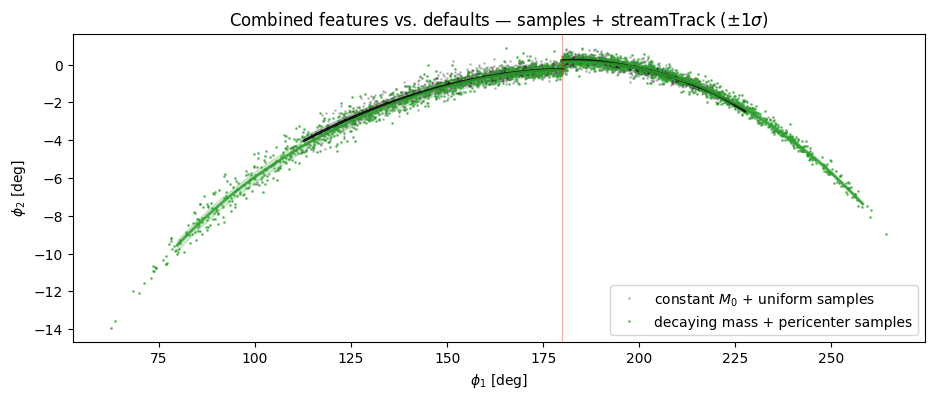

In [9]:
spdf_both = chen24spraydf(
    progenitor_mass=M_decaying,
    progenitor=prog, pot=lp,
    tdisrupt=tdisrupt,
    stripping_pdf=peri_pdf,
    tail='both', ro=ro, vo=vo,
)
numpy.random.seed(4)
stream_both = spdf_both.sample(n=2000)
phi1_b, phi2_b = aligned(stream_both)

numpy.random.seed(44)
track_both = spdf_both.streamTrack(n=500, custom_sky_transform=T_orbit)

fig, ax = plt.subplots(figsize=(11, 4))
plt.sca(ax)
ax.plot(phi1_u, phi2_u, 'k.', ms=2, alpha=0.2, label='constant $M_0$ + uniform samples')
ax.plot(phi1_b, phi2_b, 'C2.', ms=2, alpha=0.6, label='decaying mass + pericenter samples')
_draw_track(ax, track_uniform, 'k')
_draw_track(ax, track_both, 'C2')
ax.axvline(180, color='r', lw=0.5, alpha=0.5)
ax.set_xlabel(r'$\phi_1$ [deg]')
ax.set_ylabel(r'$\phi_2$ [deg]')
ax.legend(loc='best')
ax.set_title('Combined features vs. defaults — samples + streamTrack (±1$\\sigma$)');

## Summary

| Knob | Type | Time convention | Quantity-aware |
|---|---|---|---|
| `progenitor_mass` (was scalar) | scalar **or** callable `M(t)` | `t=0` now, `t<0` past | input + output, auto-detected |
| `stripping_pdf` (new) | callable `f(t)` over `[-tdisrupt, 0]` | same | same |
| `pericenter_stripping_pdf(...)` (new helper) | factory returning a `stripping_pdf` callable | same | `sigma` & `tdisrupt` may be Quantity |

Both features default to the previous behaviour when not set, so the change is fully backward compatible. The orbit-aligned (φ₁, φ₂) frame from `Orbit.align_to_orbit()` is what made differences readable — it un-projects the orbital sweep so the perpendicular stream width is on its own axis.